# Yapay Sinir Ağları (ANN) ile Görüntü Sınıflandırması

Öncelikle bir veri kümesi yüklememiz gerekiyor. Bu Görüntü Sınıflandırma modelinde Fashion MNIST'i ele alacağız . Her biri 28 x 28 piksel olan 60.000 gri tonlamalı görüntüden oluşan bir formata sahip, 10 sınıfa sahip. Bu göreve başlamak için bazı gerekli kütüphaneleri içe aktaralım:

In [1]:
# Common imports
import numpy as np
import os

# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

In [2]:
import tensorflow as tf
from tensorflow import keras
fashion_mnist = keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

2024-11-01 00:49:20.073838: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-11-01 00:49:20.093036: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-01 00:49:20.106712: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-01 00:49:20.110829: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-01 00:49:20.123186: I tensorflow/core/platform/cpu_feature_guar

In [3]:
X_train_full.shape

(60000, 28, 28)

In [4]:
X_train_full.dtype

dtype('uint8')

In [5]:
X_valid, X_train = X_train_full[:5000] / 255., X_train_full[5000:] / 255.
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.

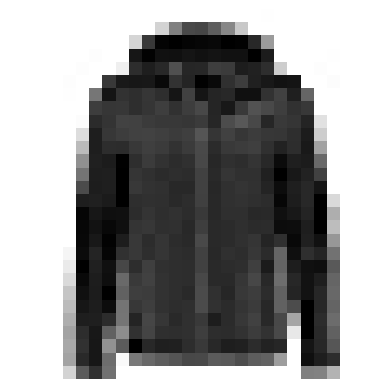

In [6]:
plt.imshow(X_train[0], cmap="binary")
plt.axis('off')
plt.show()

In [7]:
y_train

array([4, 0, 7, ..., 3, 0, 5], dtype=uint8)

In [8]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [9]:
class_names[y_train[0]]

'Coat'

In [10]:
X_valid.shape

(5000, 28, 28)

In [11]:
X_test.shape

(10000, 28, 28)

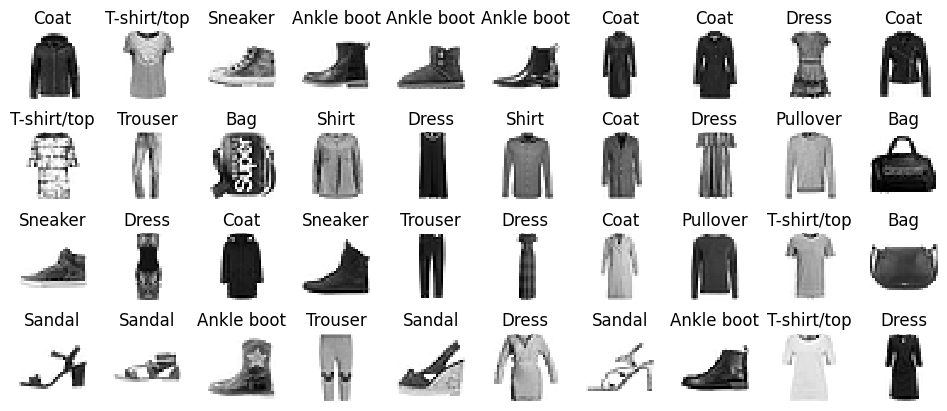

In [12]:
n_rows = 4
n_cols = 10
plt.figure(figsize=(n_cols * 1.2, n_rows * 1.2))
for row in range(n_rows):
    for col in range(n_cols):
        index = n_cols * row + col
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(X_train[index], cmap="binary", interpolation="nearest")
        plt.axis('off')
        plt.title(class_names[y_train[index]], fontsize=12)
plt.subplots_adjust(wspace=0.2, hspace=0.5)


def save_fig(param, tight_layout):
    pass


save_fig('fashion_mnist_plot', tight_layout=False)
plt.show()

In [13]:
model = keras.models.Sequential()
model.add(keras.layers.Flatten(input_shape=[28, 28]))
model.add(keras.layers.Dense(300, activation="relu"))
model.add(keras.layers.Dense(100, activation="relu"))
model.add(keras.layers.Dense(10, activation="softmax"))
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [14]:
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
pip install pydot dot


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
#pip install --upgrade pydot graphviz

In [18]:
#pip show pydot

In [32]:
import pydot
pydot.Dot.create(pydot.Dot())

b"%!PS-Adobe-3.0\n%%Creator: graphviz version 2.43.0 (0)\n%%Title: G\n%%Pages: (atend)\n%%BoundingBox: (atend)\n%%EndComments\nsave\n%%BeginProlog\n/DotDict 200 dict def\nDotDict begin\n\n/setupLatin1 {\nmark\n/EncodingVector 256 array def\n EncodingVector 0\n\nISOLatin1Encoding 0 255 getinterval putinterval\nEncodingVector 45 /hyphen put\n\n% Set up ISO Latin 1 character encoding\n/starnetISO {\n        dup dup findfont dup length dict begin\n        { 1 index /FID ne { def }{ pop pop } ifelse\n        } forall\n        /Encoding EncodingVector def\n        currentdict end definefont\n} def\n/Times-Roman starnetISO def\n/Times-Italic starnetISO def\n/Times-Bold starnetISO def\n/Times-BoldItalic starnetISO def\n/Helvetica starnetISO def\n/Helvetica-Oblique starnetISO def\n/Helvetica-Bold starnetISO def\n/Helvetica-BoldOblique starnetISO def\n/Courier starnetISO def\n/Courier-Oblique starnetISO def\n/Courier-Bold starnetISO def\n/Courier-BoldOblique starnetISO def\ncleartomark\n} bind d

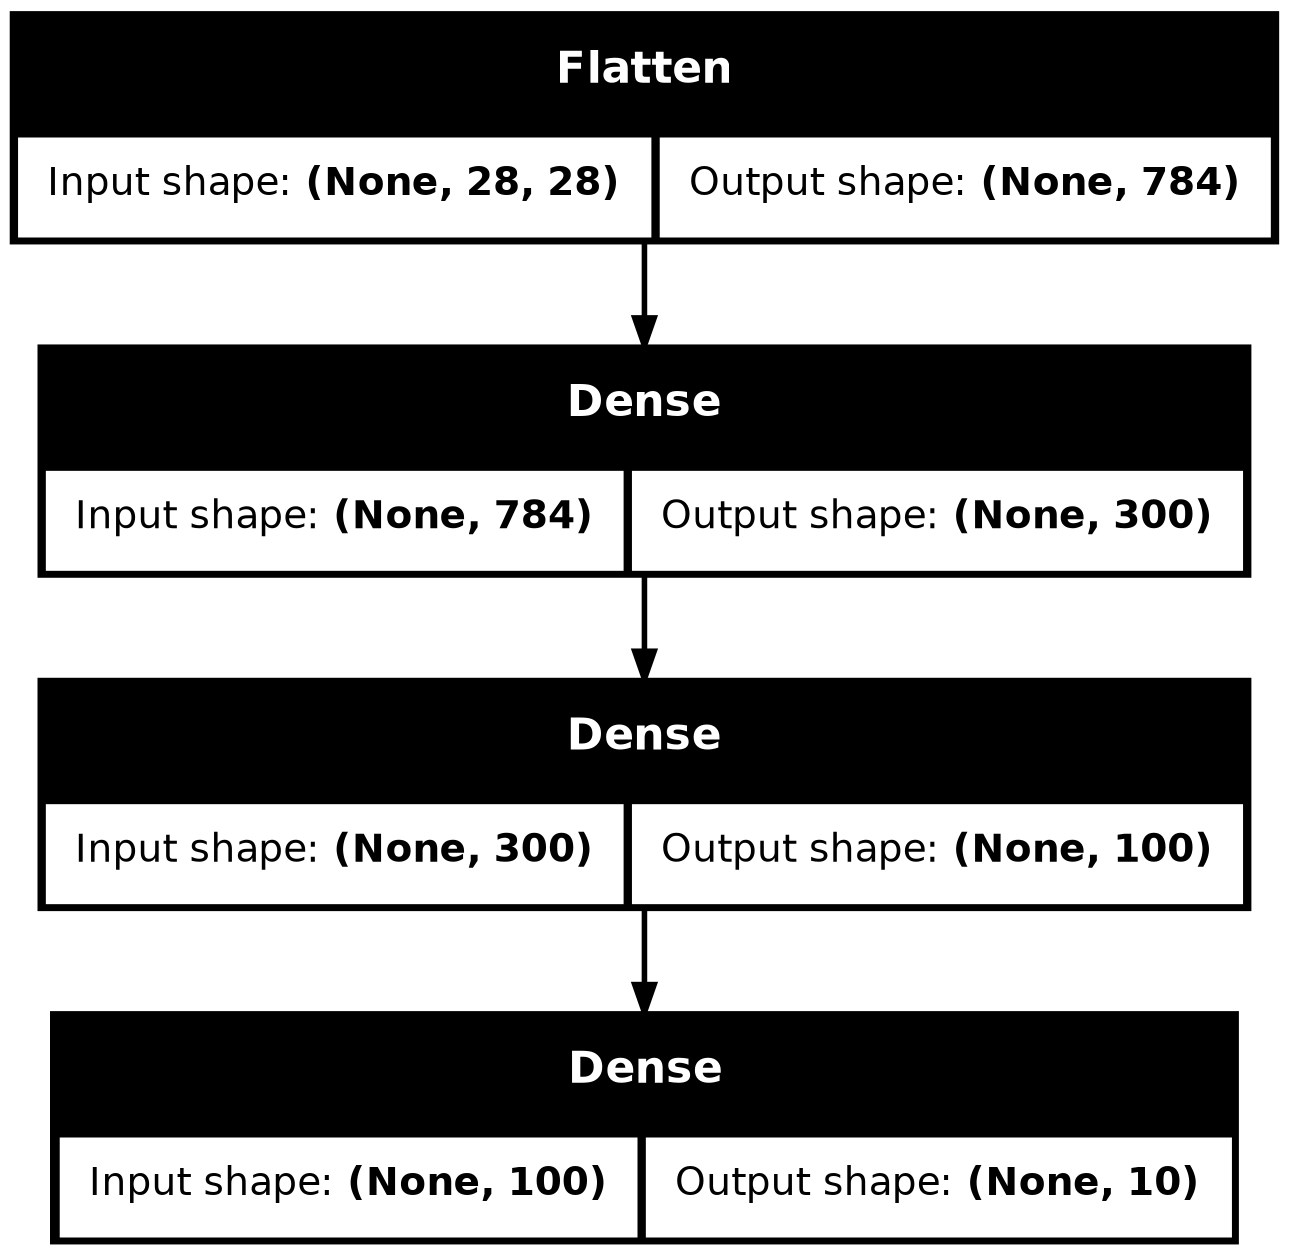

In [35]:
keras.utils.plot_model(model, "my_fashion_mnist_model.png", show_shapes=True)

In [36]:
hidden1 = model.layers[1]
hidden1.name

'dense'

In [37]:
model.get_layer(hidden1.name) is hidden1

True

In [38]:
weights, biases = hidden1.get_weights()

In [39]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [40]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [41]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6979 - loss: 0.9632 - val_accuracy: 0.8286 - val_loss: 0.5077
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8275 - loss: 0.4956 - val_accuracy: 0.8460 - val_loss: 0.4464
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8437 - loss: 0.4437 - val_accuracy: 0.8542 - val_loss: 0.4180
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8541 - loss: 0.4148 - val_accuracy: 0.8600 - val_loss: 0.3978
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8611 - loss: 0.3937 - val_accuracy: 0.8638 - val_loss: 0.3823
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8661 - loss: 0.3771 - val_accuracy: 0.8668 - val_loss: 0.3706
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8706 - loss: 0.3633 - val_accuracy: 0.8704 - val_loss: 0.3602
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8744 - loss: 0.3514 - 

TypeError: save_fig() missing 1 required positional argument: 'tight_layout'

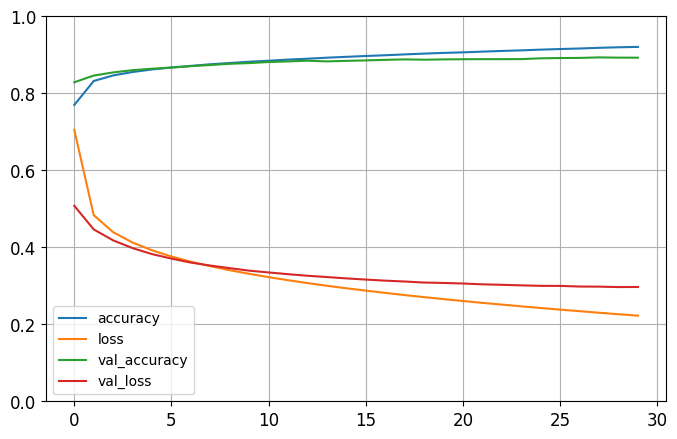

In [42]:
import pandas as pd

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
save_fig("keras_learning_curves_plot")
plt.show()

In [43]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step - accuracy: 0.8750 - loss: 0.3477


[0.34325364232063293, 0.8787000179290771]

In [44]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.01, 0.  , 0.97],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [46]:
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


array([[9.5486985e-07, 7.7367179e-07, 2.4334011e-07, 3.5498638e-06,
        3.0729741e-06, 1.4493621e-02, 4.7527669e-06, 1.4240187e-02,
        2.1378315e-04, 9.7103900e-01],
       [1.2423022e-05, 2.2675899e-09, 9.9808717e-01, 2.6711453e-09,
        1.7440039e-03, 5.6737422e-13, 1.5640495e-04, 2.0171523e-12,
        2.8382839e-08, 1.0903380e-14],
       [1.3464853e-06, 9.9999833e-01, 1.6888370e-08, 6.0485355e-08,
        1.8609775e-07, 5.6646181e-12, 2.4297972e-08, 3.4335279e-10,
        9.5829356e-10, 1.9945647e-12]], dtype=float32)

In [48]:
print("y_pred:", y_pred)
print("y_pred türü:", y_pred.dtype)  # dtype'ı kontrol et

y_pred: [[9.5486985e-07 7.7367179e-07 2.4334011e-07 3.5498638e-06 3.0729741e-06
  1.4493621e-02 4.7527669e-06 1.4240187e-02 2.1378315e-04 9.7103900e-01]
 [1.2423022e-05 2.2675899e-09 9.9808717e-01 2.6711453e-09 1.7440039e-03
  5.6737422e-13 1.5640495e-04 2.0171523e-12 2.8382839e-08 1.0903380e-14]
 [1.3464853e-06 9.9999833e-01 1.6888370e-08 6.0485355e-08 1.8609775e-07
  5.6646181e-12 2.4297972e-08 3.4335279e-10 9.5829356e-10 1.9945647e-12]]
y_pred türü: float32


In [49]:
# Eğer y_pred float ise, tam sayıya dönüştür
y_pred = y_pred.astype(int)

In [50]:
np.array(class_names)[y_pred]

array([['T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top'],
       ['T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top'],
       ['T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top',
        'T-shirt/top', 'T-shirt/top']], dtype='<U11')

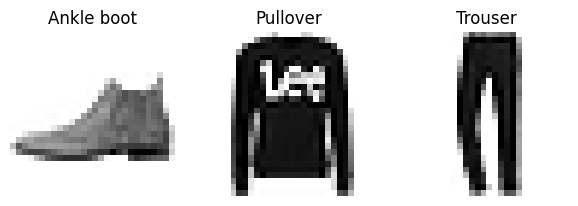

In [51]:
y_new = y_test[:3]
plt.figure(figsize=(7.2, 2.4))
for index, image in enumerate(X_new):
    plt.subplot(1, 3, index + 1)
    plt.imshow(image, cmap="binary", interpolation="nearest")
    plt.axis('off')
    plt.title(class_names[y_test[index]], fontsize=12)
plt.subplots_adjust(wspace=0.2, hspace=0.5)
save_fig('fashion_mnist_images_plot', tight_layout=False)
plt.show()

In [53]:
model.save('model.keras')

Burada sınıflandırma modeli aslında üç görüntüyü de doğru şekilde sınıflandırdı